# Análisis exploratorio de datos (EDA)

Dataset de entrenamiento: `database/raw/intenciones.csv`: frases de clientes y administradores de una tienda de ropa, etiquetadas con una de las 13 intenciones del plan.

Contenido (enunciado, sección 5.1):

1. Estructura del archivo y **valores faltantes**.
2. **Distribución de clases** (por intención, por rol y por origen).
3. **Longitud de los textos**.
4. **Palabras más frecuentes**, en general y por intención.
5. División entrenamiento / prueba **estratificada con semilla fija** y tratamiento del desbalance.
6. Datasets complementarios (`docs/datasets/`).

In [1]:
import os, sys
from collections import Counter
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import config
from src.data.dataset import cargar_intenciones, dividir
from src.nlp.normalizacion import normalizar
from src.nlp.tokenizacion import tokenizar
from src.nlp.stopwords import quitar_stopwords

pd.set_option("display.max_colwidth", 80)
COLOR = "#6a46a8"   # color de las barras (una sola serie por gráfico)
RUTA = Path(config["data"]["raw_path"])
SEED = config["project"]["seed"]

def estilo(eje):
    # Ejes discretos: sin bordes superiores/derechos y con grilla suave
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="x", color="#e5e1da", linewidth=0.8)
    eje.set_axisbelow(True)

## 1. Estructura del archivo y valores faltantes

In [2]:
crudo = pd.read_csv(RUTA, encoding="utf-8")   # tal como está en disco, sin limpiar
print(f"Archivo: {RUTA}  ·  {len(crudo)} filas  ·  {crudo.shape[1]} columnas")
print("Columnas:", list(crudo.columns))
crudo.head(8)

Archivo: ..\database\raw\intenciones.csv  ·  1120 filas  ·  4 columnas
Columnas: ['texto', 'intencion', 'rol', 'fuente']


,texto,intencion,rol,fuente
0,hola buenas tardes,saludo,cliente,manual
1,hola como estan,saludo,cliente,manual
2,buenos dias,saludo,cliente,manual
3,buenas noches quisiera hacer una consulta,saludo,cliente,manual
4,hola que tal,saludo,cliente,manual
5,hey buenas,saludo,cliente,manual
6,hola asistente,saludo,cliente,manual
7,buen dia necesito ayuda,saludo,cliente,manual


In [3]:
faltantes = pd.DataFrame({
    "valores faltantes": crudo.isna().sum(),
    "textos vacíos": [(crudo[c].astype(str).str.strip() == "").sum() for c in crudo.columns],
})
print(f"Filas duplicadas (mismo texto): {crudo.duplicated(subset=['texto']).sum()}")
print(f"Mismo texto con distinta intención: {crudo.groupby('texto')['intencion'].nunique().gt(1).sum()}")
faltantes

Filas duplicadas (mismo texto): 0
Mismo texto con distinta intención: 0


,valores faltantes,textos vacíos
texto,0,0
intencion,0,0
rol,0,0
fuente,0,0


In [4]:
# Después de la carga del proyecto (src/data/dataset.py): quita vacíos y duplicados
df = cargar_intenciones(RUTA)
print(f"Filas para modelar: {len(df)} (se descartaron {len(crudo) - len(df)})")

Filas para modelar: 1120 (se descartaron 0)


## 2. Distribución de clases

In [5]:
conteo = df["intencion"].value_counts().sort_index()
rol_de = df.groupby("intencion")["rol"].first()
tabla = pd.DataFrame({"frases": conteo, "% del total": (conteo / len(df) * 100).round(1), "rol": rol_de})
print(f"{df['intencion'].nunique()} intenciones · mínimo {conteo.min()} · máximo {conteo.max()} frases por intención")
tabla.sort_values(["rol", "frases"], ascending=[True, False])

14 intenciones · mínimo 80 · máximo 80 frases por intención


,frases,% del total,rol
intencion,,,
productos_mas_vendidos,80,7.1,admin
reporte_ventas,80,7.1,admin
stock_bajo,80,7.1,admin
ventas_por_categoria,80,7.1,admin
consultar_precio,80,7.1,cliente
consultar_stock,80,7.1,cliente
consultar_tallas,80,7.1,cliente
despedida,80,7.1,cliente
devoluciones,80,7.1,cliente


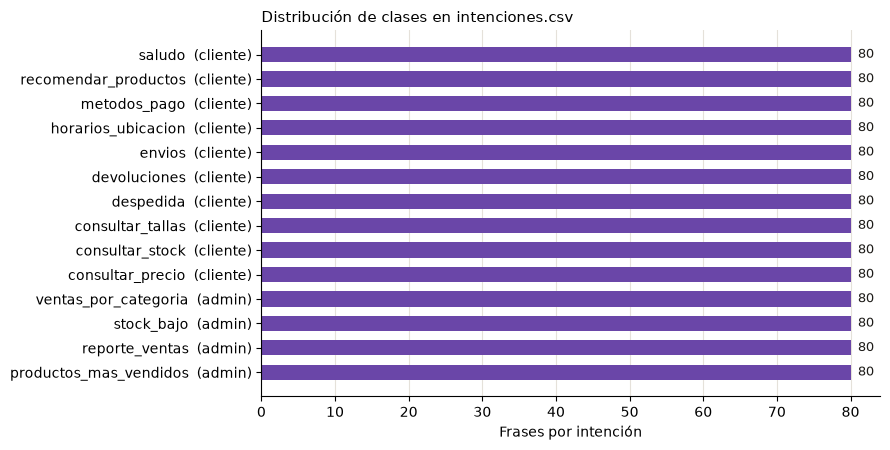

In [6]:
fig, eje = plt.subplots(figsize=(9, 4.6))
orden = tabla.sort_values(["rol", "frases"]).index
eje.barh([f"{i}  ({rol_de[i]})" for i in orden], conteo[orden], color=COLOR, height=0.62)
for y, valor in enumerate(conteo[orden]):
    eje.text(valor + 1, y, str(valor), va="center", fontsize=9, color="#1d1b18")
eje.set_xlabel("Frases por intención")
eje.set_title("Distribución de clases en intenciones.csv", loc="left", fontsize=11)
estilo(eje)
plt.tight_layout()
plt.show()

In [7]:
pd.crosstab(df["rol"], df["fuente"], margins=True, margins_name="total")

fuente,ia,manual,total
rol,,,
admin,280,40,320
cliente,702,98,800
total,982,138,1120


**Origen (`fuente`):** `manual` son frases escritas por el grupo y `ia` frases generadas con un asistente de IA y revisadas por el grupo. El enunciado permite el uso de IA con declaración en el informe.

In [8]:
pd.crosstab(df["intencion"], df["fuente"]).assign(**{"% ia": lambda t: (t["ia"] / t.sum(axis=1) * 100).round(0)})

fuente,ia,manual,% ia
intencion,,,
consultar_precio,69,11,86.0
consultar_stock,68,12,85.0
consultar_tallas,69,11,86.0
despedida,69,11,86.0
devoluciones,70,10,88.0
envios,69,11,86.0
horarios_ubicacion,70,10,88.0
metodos_pago,70,10,88.0
productos_mas_vendidos,70,10,88.0


## 3. Longitud de los textos

In [9]:
df["palabras"] = df["texto"].str.split().str.len()
df["caracteres"] = df["texto"].str.len()
resumen = df.groupby("intencion")["palabras"].agg(["mean", "median", "min", "max"]).round(1)
resumen.columns = ["media", "mediana", "mínimo", "máximo"]
print("Palabras por frase (todo el dataset):", df["palabras"].describe().round(1).to_dict())
resumen.sort_values("media")

Palabras por frase (todo el dataset): {'count': 1120.0, 'mean': 8.4, 'std': 2.6, 'min': 2.0, '25%': 6.0, '50%': 8.0, '75%': 10.0, 'max': 16.0}


,media,mediana,mínimo,máximo
intencion,,,,
saludo,5.7,6.0,2,9
recomendar_productos,5.9,6.0,3,10
despedida,6.1,6.0,3,10
consultar_stock,6.4,6.0,3,9
consultar_precio,7.3,7.0,5,10
consultar_tallas,7.9,8.0,4,12
envios,8.4,8.0,4,12
horarios_ubicacion,8.6,8.5,2,13
metodos_pago,8.8,9.0,3,13


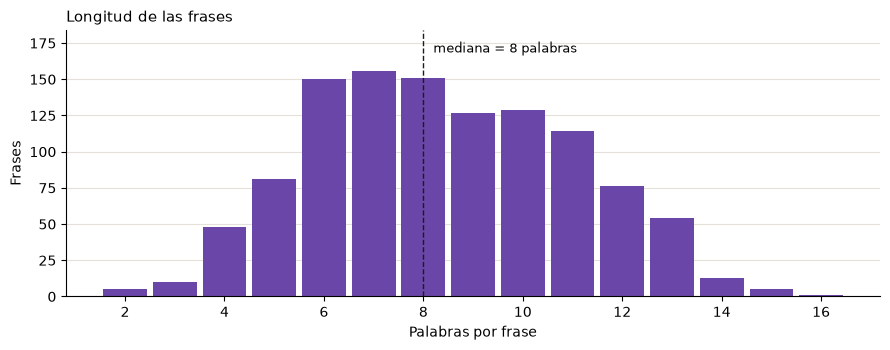

In [10]:
fig, eje = plt.subplots(figsize=(9, 3.6))
limites = np.arange(df["palabras"].min(), df["palabras"].max() + 2) - 0.5
alturas, _, _ = eje.hist(df["palabras"], bins=limites, color=COLOR, rwidth=0.88)
eje.set_ylim(0, alturas.max() * 1.18)  # espacio libre arriba para la etiqueta de la mediana
eje.axvline(df["palabras"].median(), color="#1d1b18", linewidth=1, linestyle="--")
eje.text(df["palabras"].median() + 0.2, alturas.max() * 1.08, f"mediana = {df['palabras'].median():.0f} palabras", fontsize=9)
eje.set_xlabel("Palabras por frase")
eje.set_ylabel("Frases")
eje.set_title("Longitud de las frases", loc="left", fontsize=11)
eje.spines[["top", "right"]].set_visible(False)
eje.grid(axis="y", color="#e5e1da", linewidth=0.8)
eje.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [11]:
print("Frases más cortas:")
display(df.nsmallest(5, "palabras")[["texto", "intencion", "palabras"]])
print("Frases más largas:")
display(df.nlargest(5, "palabras")[["texto", "intencion", "palabras"]])

Frases más cortas:


,texto,intencion,palabras
2,buenos dias,saludo,2
5,hey buenas,saludo,2
6,hola asistente,saludo,2
11,hola amigos,saludo,2
82,atienden feriados?,horarios_ubicacion,2


Frases más largas:


,texto,intencion,palabras
1034,cual es el aporte de la categoria de vestidos cortos al margen neto de la em...,ventas_por_categoria,16
948,cuales prendas de vestir presentan quiebre en mas del 50 por ciento de sus t...,stock_bajo,15
974,cuanto se vendio en la categoria de ropa formal en lo que va del trimestre,ventas_por_categoria,15
981,cual es el volumen de ventas en la division de trajes de baño y verano,ventas_por_categoria,15
1002,cual fue la variacion porcentual en ventas de la linea formal respecto al me...,ventas_por_categoria,15


## 4. Palabras más frecuentes

Se cuentan después de normalizar, tokenizar y quitar stop words (fases 1 a 3 del pipeline), porque sin eso las más frecuentes serían "de", "la", "en".

In [12]:
df["tokens"] = [quitar_stopwords(tokenizar(normalizar(t))) for t in df["texto"]]
todas = Counter(t for tokens in df["tokens"] for t in tokens)
print(f"Tokens totales: {sum(todas.values())} · palabras distintas: {len(todas)} · aparecen una sola vez: {sum(1 for n in todas.values() if n == 1)}")
pd.DataFrame(todas.most_common(20), columns=["palabra", "veces"]).T

Tokens totales: 5422 · palabras distintas: 1486 · aparecen una sola vez: 810


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
palabra,tienen,ventas,cuanto,dame,cual,talla,muestrame,gracias,ropa,prendas,cuales,tienda,hola,mas,hasta,categoria,como,buenas,stock,productos
veces,150,98,86,77,72,57,54,52,52,51,50,47,46,44,39,37,36,35,35,33


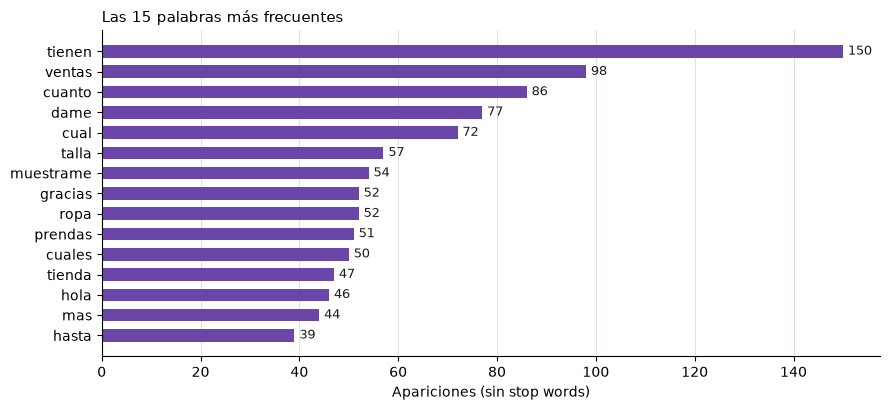

In [13]:
fig, eje = plt.subplots(figsize=(9, 4.2))
top = todas.most_common(15)[::-1]
eje.barh([p for p, _ in top], [n for _, n in top], color=COLOR, height=0.62)
for y, (_, n) in enumerate(top):
    eje.text(n + 1, y, str(n), va="center", fontsize=9, color="#1d1b18")
eje.set_xlabel("Apariciones (sin stop words)")
eje.set_title("Las 15 palabras más frecuentes", loc="left", fontsize=11)
estilo(eje)
plt.tight_layout()
plt.show()

In [14]:
# Las 6 palabras más frecuentes de cada intención: muestran qué palabras la distinguen
por_intencion = {
    intencion: ", ".join(f"{p} ({n})" for p, n in Counter(t for tokens in grupo["tokens"] for t in tokens).most_common(6))
    for intencion, grupo in df.groupby("intencion")
}
pd.Series(por_intencion, name="palabras más frecuentes (veces)").to_frame()

,palabras más frecuentes (veces)
consultar_precio,"cuanto (39), precio (20), cuesta (11), cual (11), tiene (8), sale (8)"
consultar_stock,"tienen (41), hay (20), stock (14), disponibles (9), queda (9), existencia (8)"
consultar_tallas,"talla (48), tienen (38), tallas (18), vienen (7), viene (7), hay (5)"
despedida,"gracias (52), hasta (27), luego (20), chau (13), adios (12), vemos (9)"
devoluciones,"prenda (18), cambio (18), devolucion (15), cambiar (11), no (10), cambios (7)"
envios,"envio (18), cuanto (12), envios (11), paquete (10), tienen (8), entregas (7)"
horarios_ubicacion,"tienen (16), cual (15), tienda (14), hora (13), horario (9), donde (8)"
metodos_pago,"pagar (21), aceptan (18), pago (17), tienen (12), pagos (8), tarjeta (8)"
productos_mas_vendidos,"mas (35), cuales (23), mayor (22), dame (19), prendas (14), productos (14)"
recomendar_productos,"recomiendas (24), recomiendame (11), sugieres (9), prenda (5), ropa (5), cua..."


In [15]:
# Palabras compartidas por muchas intenciones: son las que generan confusión entre clases
intenciones_por_palabra = Counter()
for intencion, grupo in df.groupby("intencion"):
    for palabra in set(t for tokens in grupo["tokens"] for t in tokens):
        intenciones_por_palabra[palabra] += 1
compartidas = [(p, n, todas[p]) for p, n in intenciones_por_palabra.most_common(12)]
pd.DataFrame(compartidas, columns=["palabra", "intenciones donde aparece", "veces"])

,palabra,intenciones donde aparece,veces
0,tienda,13,47
1,prendas,12,51
2,ropa,11,52
3,tienen,10,150
4,como,9,36
5,verano,8,10
6,cual,8,72
7,vestir,8,16
8,coleccion,8,8
9,semana,8,29


## 5. División entrenamiento / prueba y desbalance

`src/data/dataset.py` divide 80/20 de forma **estratificada** (cada intención conserva su proporción en ambos conjuntos) y con **semilla fija**, para que la división sea siempre la misma. El conjunto de prueba solo se usa al final para informar métricas.

In [16]:
X_train, X_test, y_train, y_test = dividir(df, test_size=config["data"]["test_size"], seed=SEED)
particion = pd.DataFrame({"entrenamiento": y_train.value_counts(), "prueba": y_test.value_counts()}).sort_index()
particion["% en prueba"] = (particion["prueba"] / (particion["entrenamiento"] + particion["prueba"]) * 100).round(1)
print(f"Semilla {SEED} · entrenamiento {len(X_train)} · prueba {len(X_test)}")
particion

Semilla 42 · entrenamiento 896 · prueba 224


,entrenamiento,prueba,% en prueba
intencion,,,
consultar_precio,64,16,20.0
consultar_stock,64,16,20.0
consultar_tallas,64,16,20.0
despedida,64,16,20.0
devoluciones,64,16,20.0
envios,64,16,20.0
horarios_ubicacion,64,16,20.0
metodos_pago,64,16,20.0
productos_mas_vendidos,64,16,20.0


In [17]:
# La misma frase nunca queda en los dos conjuntos (evita medir con frases ya vistas)
print("Frases repetidas entre entrenamiento y prueba:", len(set(X_train) & set(X_test)))

Frases repetidas entre entrenamiento y prueba: 0


## 6. Datasets complementarios (`docs/datasets/`)

Además del dataset del grupo se construyeron tres datasets a partir de fuentes públicas, con origen, licencia y fecha documentados en `docs/datasets/README.md`.

In [18]:
d1 = pd.read_excel("../docs/datasets/dataset_1_intenciones_atencion_cliente.xlsx", sheet_name="frases")
d2 = pd.read_excel("../docs/datasets/dataset_2_consultas_fuera_de_dominio.xlsx", sheet_name="consultas")
d3p = pd.read_excel("../docs/datasets/dataset_3_inventario_ventas_amazon.xlsx", sheet_name="productos")
d3v = pd.read_excel("../docs/datasets/dataset_3_inventario_ventas_amazon.xlsx", sheet_name="ventas")
pd.DataFrame([
    ("1. Intenciones (Bitext ES, CDLA-Sharing-1.0)", len(d1), ", ".join(f"{k}: {v}" for k, v in d1["intencion"].value_counts().items())),
    ("2. Fuera de dominio (MASSIVE es-ES CC BY 4.0 + Bitext)", len(d2), ", ".join(f"{k}: {v}" for k, v in d2["dificultad"].value_counts().items())),
    ("3a. Productos (Amazon Reviews'23)", len(d3p), f"{d3p['categoria'].nunique()} categorías"),
    ("3b. Ventas (compras verificadas)", len(d3v), f"del {d3v['fecha'].min()} al {d3v['fecha'].max()}"),
], columns=["dataset", "filas", "detalle"])

,dataset,filas,detalle
0,"1. Intenciones (Bitext ES, CDLA-Sharing-1.0)",6320,"envios: 2947, devoluciones: 1745, metodos_pago: 1628"
1,2. Fuera de dominio (MASSIVE es-ES CC BY 4.0 + Bitext),25538,"facil: 15872, dificil: 9666"
2,3a. Productos (Amazon Reviews'23),8000,16 categorías
3,3b. Ventas (compras verificadas),15000,del 2022-11-25 al 2023-09-10


In [19]:
# Longitud del dataset 1 frente al del grupo: las frases reales de Bitext son parecidas en tamaño
d1["palabras"] = d1["texto"].astype(str).str.split().str.len()
pd.DataFrame({
    "grupo (intenciones.csv)": df["palabras"].describe().round(1),
    "Bitext (dataset 1)": d1["palabras"].describe().round(1),
})

,grupo (intenciones.csv),Bitext (dataset 1)
count,1120.0,6320.0
mean,8.4,8.5
std,2.6,2.1
min,2.0,2.0
25%,6.0,7.0
50%,8.0,9.0
75%,10.0,10.0
max,16.0,75.0


## Conclusiones del análisis exploratorio

**Calidad de los datos.** Las 1.120 frases no tienen valores faltantes, textos vacíos ni duplicados, y ninguna frase aparece con dos intenciones distintas. No hizo falta descartar filas.

**Distribución de clases y desbalance.** Las 14 intenciones tienen exactamente 80 frases (7,1 % cada una). El dataset está **balanceado** porque se construyó con una meta fija por intención (plan, sección 3.1). Por eso:
- No se aplica sobremuestreo ni submuestreo.
- La métrica principal es igual el **F1 macro**, que pesa por igual cada intención y seguiría siendo correcta si se agregan frases de forma desigual (por ejemplo, las del dataset 1 de Bitext).
- `train.py` prueba `class_weight = None` y `"balanced"`; con clases del mismo tamaño ambos dan los mismos pesos, así que la elección no cambia el modelo.

Hay 10 intenciones de cliente (800 frases) y 4 de administración (320).

**Intención agregada: `recomendar_productos`.** Las 13 intenciones del plan no cubrían preguntas como "¿qué me recomiendas?", que el modelo respondía con "no entendí" (35 % de confianza). Se agregó una intención 14 con 80 frases (`fuente = ia`). En la prueba su F1 es 0,85 y casi no se confunde con otras intenciones.

**Origen.** El 88 % de las frases (982) se generó con IA y el 12 % (138) se escribió a mano. Se declara en el informe. Para sumar datos de una fuente pública real, el dataset 1 aporta 6.320 frases de Bitext para `envios`, `devoluciones` y `metodos_pago`.

**Longitud.** Las frases son cortas: 8,4 palabras en promedio (mediana 8, entre 2 y 16). La longitud varía según la intención:
- Las más cortas son saludos, despedidas y recomendaciones (≈6 palabras).
- Las más largas son las consultas de administración (10 a 12 palabras, por ejemplo "ventas por categoría del trimestre").

Con frases tan cortas cada palabra pesa mucho, y por eso importan las decisiones de stop words (notebook 02b).

**Palabras más frecuentes.** Cada intención tiene palabras propias muy claras: `gracias`, `hasta` y `luego` en despedida; `talla` en consultar_tallas; `pagar` y `aceptan` en métodos de pago; `ventas` en los reportes. Esas palabras explican el buen F1 general. Las confusiones esperables vienen de palabras compartidas:
- `tienen` es la palabra más frecuente (150 veces) y aparece en 10 intenciones: sola no alcanza para distinguir `consultar_stock` de `consultar_tallas` u `horarios_ubicacion`.
- `ventas`, `dame`, `muestrame` y `cuanto` se reparten entre las 4 intenciones de administración, que son las que más se confunden entre sí (notebook 03).
- 810 de las 1.486 palabras distintas aparecen una sola vez: el vocabulario es disperso. Por eso conviene unir variantes de una palabra (lematización o stemming) y usar bigramas en TF-IDF (fase 5).

**División.** Entrenamiento 896 y prueba 224 frases, estratificada (16 frases de prueba por intención, 20 % exacto) con semilla 42. Ninguna frase aparece en ambos conjuntos, así que la prueba mide frases nunca vistas. Con solo 16 frases por intención, el resultado de prueba varía varios puntos según qué frases caigan en ese conjunto; por eso las decisiones se toman con validación cruzada.